In [1]:
import numpy as np
import matplotlib as mpl

In [2]:
from pdadic import NAryTree
from pdadic import QTreeMap

from pdadic.examples import PowerKernelOperator
from pdadic.examples import GaussianKernelOperator

from pdadic.ploting import PlotParameters
from pdadic.ploting import EvolutionDiscussion
from pdadic.ploting import show

In [17]:
mpl.rcParams["text.usetex"] = True
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = "16"
mpl.rcParams["text.latex.preamble"] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
\usepackage{bm}
\usepackage{lmodern}  % Optional: for better scaling of Computer Modern
"""

In [18]:
HEIGHT = 4
DEGREE = 3

qtree = NAryTree(DEGREE, HEIGHT)
func = lambda x: np.exp(-2**4 * (x - 0.5)**2)
qfunc = QTreeMap.from_function(qtree, func)
# qdecomp = qfunc.to_decomposition()

In [19]:
PARAMS = PlotParameters(
    columns         = 1,
    subplot_height  = 4,
    subplot_width   = 6,
    margin_top      = .9,
)


def discuss_operators(operators, labels, dilations):
    for op, label ,rho in zip(operators, labels, dilations):
        discussion = EvolutionDiscussion(op, qfunc,
            dilation=rho,
            params=PARAMS,
        ).single(label + fr", $\rho={rho}$")
        print("The eigenvalues are:")
        print(op.eigenvalues)
        show(discussion)

self.T=np.float64(15.232)
The eigenvalues are:
[0.43869134 0.48491098 0.56681333 0.70438988]


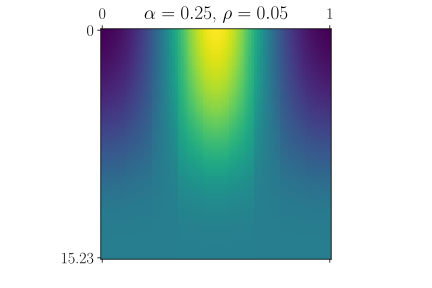

self.T=np.float64(11.36)
The eigenvalues are:
[0.57735027 0.71823351 0.98741682 1.53080056]


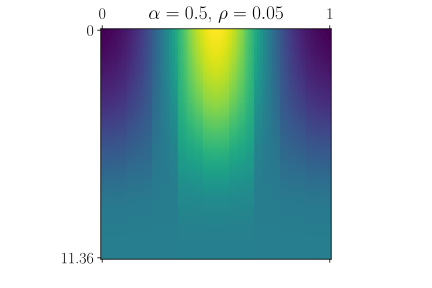

self.T=np.float64(6.473520000000001)
The eigenvalues are:
[1.         1.66666667 3.22222222 7.74074074]


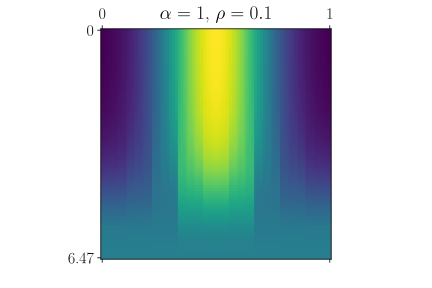

self.T=np.float64(2.156)
The eigenvalues are:
[  3.          11.          45.66666667 249.22222222]


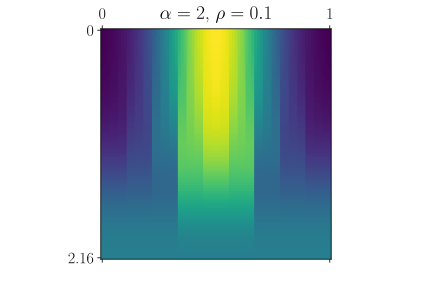

In [20]:
ALPHAS = [1/4, 1/2, 1, 2]
POWER_DILATIONS = [.05, .05, .1, .1]
power_kernel_operators = [
    PowerKernelOperator(qtree, alpha)
    for alpha in ALPHAS
]
power_kernel_labels = [
    fr"$\alpha={alpha}$"
    for alpha in ALPHAS
]

discuss_operators(
    operators   = power_kernel_operators,
    labels      = power_kernel_labels,
    dilations   = POWER_DILATIONS,
)

self.T=np.float64(33.24672)
The eigenvalues are:
[0.21016421 0.20357592 0.19456065 0.19039262]


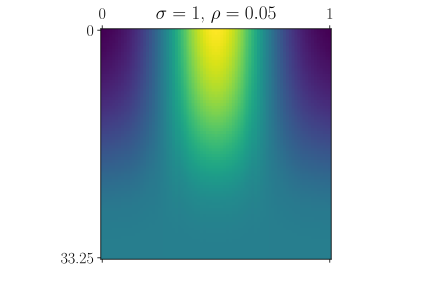

self.T=np.float64(13.616)
The eigenvalues are:
[0.58661555 0.5227993  0.4358253  0.39733752]


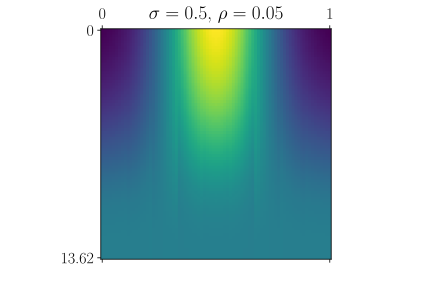

self.T=np.float64(6.328)
The eigenvalues are:
[2.15451033 1.67602216 1.02886673 0.76697508]


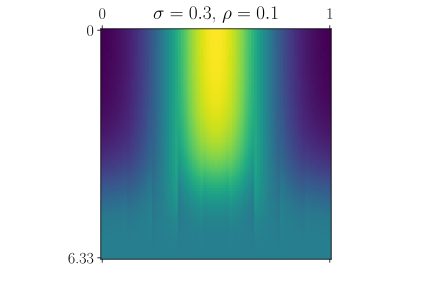

self.T=np.float64(0.308691)
The eigenvalues are:
[174.93497934 117.34673422  40.46933246  14.37555374]


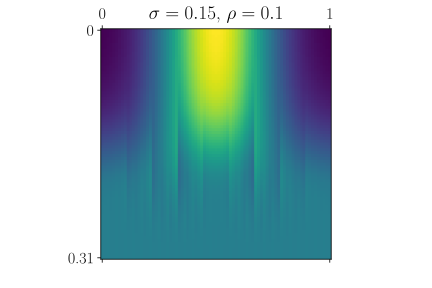

In [24]:
SIGMAS = [1, .5, .3, .15]
GAUSSIAN_DILATIONS = [0.05, 0.05, 0.1, 0.1]

gaussian_kernel_operators = [
    GaussianKernelOperator(qtree, sigma)
    for sigma in SIGMAS
]
gaussian_kernel_labels = [
    fr"$\sigma={sigma}$"
    for sigma in SIGMAS
]

discuss_operators(
    operators   = gaussian_kernel_operators,
    labels      = gaussian_kernel_labels,
    dilations   = GAUSSIAN_DILATIONS,
)